In [ ]:
!pip install pyspark

In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("FraudAnalizi").getOrCreate()

df = spark.read.csv("fraudTrain.csv", header=True, inferSchema=True)

print("Satır sayısı:", df.count())
df.printSchema()
df.show(5)

Satır sayısı: 945443
root
 |-- _c0: integer (nullable = true)
 |-- trans_date_trans_time: timestamp (nullable = true)
 |-- cc_num: long (nullable = true)
 |-- merchant: string (nullable = true)
 |-- category: string (nullable = true)
 |-- amt: double (nullable = true)
 |-- first: string (nullable = true)
 |-- last: string (nullable = true)
 |-- gender: string (nullable = true)
 |-- street: string (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- zip: integer (nullable = true)
 |-- lat: double (nullable = true)
 |-- long: double (nullable = true)
 |-- city_pop: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- dob: date (nullable = true)
 |-- trans_num: string (nullable = true)
 |-- unix_time: integer (nullable = true)
 |-- merch_lat: double (nullable = true)
 |-- merch_long: double (nullable = true)
 |-- is_fraud: integer (nullable = true)

+---+---------------------+----------------+--------------------+-------------+------

In [ ]:
from pyspark.sql import functions as F

# Gereksiz index sütununu at
df = df.drop("_c0")

# Toplam satır
toplam = df.count()
print("Toplam satır:", toplam)

# Fraud / normal dağılımı
dagilim = df.groupBy("is_fraud").count().orderBy("is_fraud")
dagilim.show()

fraud_sayisi = df.filter(F.col("is_fraud") == 1).count()
print(f"Fraud oranı: %{fraud_sayisi / toplam * 100:.3f}")

# Eksik değer kontrolü
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show(vertical=True)

Toplam satır: 945443
+--------+------+
|is_fraud| count|
+--------+------+
|    NULL|     1|
|       0|940075|
|       1|  5367|
+--------+------+

Fraud oranı: %0.568
-RECORD 0--------------------
 trans_date_trans_time | 1   
 cc_num                | 1   
 merchant              | 1   
 category              | 1   
 amt                   | 1   
 first                 | 1   
 last                  | 1   
 gender                | 1   
 street                | 1   
 city                  | 1   
 state                 | 1   
 zip                   | 1   
 lat                   | 1   
 long                  | 1   
 city_pop              | 1   
 job                   | 1   
 dob                   | 1   
 trans_num             | 1   
 unix_time             | 1   
 merch_lat             | 1   
 merch_long            | 1   
 is_fraud              | 1   



In [ ]:
import os
print("Dosya boyutu (MB):", os.path.getsize("fraudTrain.csv") / 1024 / 1024)

# Dosyada kaç satır var (Spark'tan bağımsız)
!wc -l fraudTrain.csv

Dosya boyutu (MB): 244.0
945443 fraudTrain.csv


In [ ]:
import os
print("Dosya boyutu (MB):", os.path.getsize("fraudTrain.csv") / 1024 / 1024)
!wc -l fraudTrain.csv

Dosya boyutu (MB): 244.0
945443 fraudTrain.csv


In [ ]:
import os
print("Dosya boyutu (MiB):", os.path.getsize("fraudTrain.csv") / 1024 / 1024)
!wc -l fraudTrain.csv

Dosya boyutu (MiB): 243.0
941564 fraudTrain.csv


In [7]:
import os
print("Dosya boyutu (MiB):", os.path.getsize("fraudTrain.csv") / 1024 / 1024)
!wc -l fraudTrain.csv

Dosya boyutu (MiB): 334.96684646606445
1296676 fraudTrain.csv


In [8]:
from pyspark.sql import functions as F

df = spark.read.csv("fraudTrain.csv", header=True, inferSchema=True)
df = df.drop("_c0")

toplam = df.count()
print("Toplam satır:", toplam)

df.groupBy("is_fraud").count().orderBy("is_fraud").show()

fraud_sayisi = df.filter(F.col("is_fraud") == 1).count()
print(f"Fraud oranı: %{fraud_sayisi / toplam * 100:.3f}")

# Eksik değer kontrolü
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show(vertical=True)

Toplam satır: 1296675
+--------+-------+
|is_fraud|  count|
+--------+-------+
|       0|1289169|
|       1|   7506|
+--------+-------+

Fraud oranı: %0.579
-RECORD 0--------------------
 trans_date_trans_time | 0   
 cc_num                | 0   
 merchant              | 0   
 category              | 0   
 amt                   | 0   
 first                 | 0   
 last                  | 0   
 gender                | 0   
 street                | 0   
 city                  | 0   
 state                 | 0   
 zip                   | 0   
 lat                   | 0   
 long                  | 0   
 city_pop              | 0   
 job                   | 0   
 dob                   | 0   
 trans_num             | 0   
 unix_time             | 0   
 merch_lat             | 0   
 merch_long            | 0   
 is_fraud              | 0   



In [9]:
df.groupBy("is_fraud").agg(
    F.count("amt").alias("adet"),
    F.round(F.mean("amt"), 2).alias("ortalama"),
    F.round(F.expr("percentile_approx(amt, 0.5)"), 2).alias("medyan"),
    F.round(F.min("amt"), 2).alias("min"),
    F.round(F.max("amt"), 2).alias("max")
).show()

+--------+-------+--------+------+----+-------+
|is_fraud|   adet|ortalama|medyan| min|    max|
+--------+-------+--------+------+----+-------+
|       1|   7506|  531.32|394.72|1.06|1376.04|
|       0|1289169|   67.67| 47.29| 1.0|28948.9|
+--------+-------+--------+------+----+-------+



In [10]:
# Kategori bazlı fraud oranı
df.groupBy("category").agg(
    F.count("*").alias("toplam"),
    F.sum("is_fraud").alias("fraud"),
    F.round(F.avg("is_fraud") * 100, 2).alias("fraud_orani_yuzde")
).orderBy(F.desc("fraud_orani_yuzde")).show(20, truncate=False)

# Saat bazlı fraud oranı
df = df.withColumn("saat", F.hour("trans_date_trans_time"))
df.groupBy("saat").agg(
    F.count("*").alias("toplam"),
    F.sum("is_fraud").alias("fraud"),
    F.round(F.avg("is_fraud") * 100, 2).alias("fraud_orani_yuzde")
).orderBy("saat").show(24)

+--------------+------+-----+-----------------+
|category      |toplam|fraud|fraud_orani_yuzde|
+--------------+------+-----+-----------------+
|shopping_net  |97543 |1713 |1.76             |
|misc_net      |63287 |915  |1.45             |
|grocery_pos   |123638|1743 |1.41             |
|shopping_pos  |116672|843  |0.72             |
|gas_transport |131659|618  |0.47             |
|misc_pos      |79655 |250  |0.31             |
|travel        |40507 |116  |0.29             |
|grocery_net   |45452 |134  |0.29             |
|entertainment |94014 |233  |0.25             |
|personal_care |90758 |220  |0.24             |
|kids_pets     |113035|239  |0.21             |
|food_dining   |91461 |151  |0.17             |
|home          |123115|198  |0.16             |
|health_fitness|85879 |133  |0.15             |
+--------------+------+-----+-----------------+

+----+------+-----+-----------------+
|saat|toplam|fraud|fraud_orani_yuzde|
+----+------+-----+-----------------+
|   0| 42502|  635|  

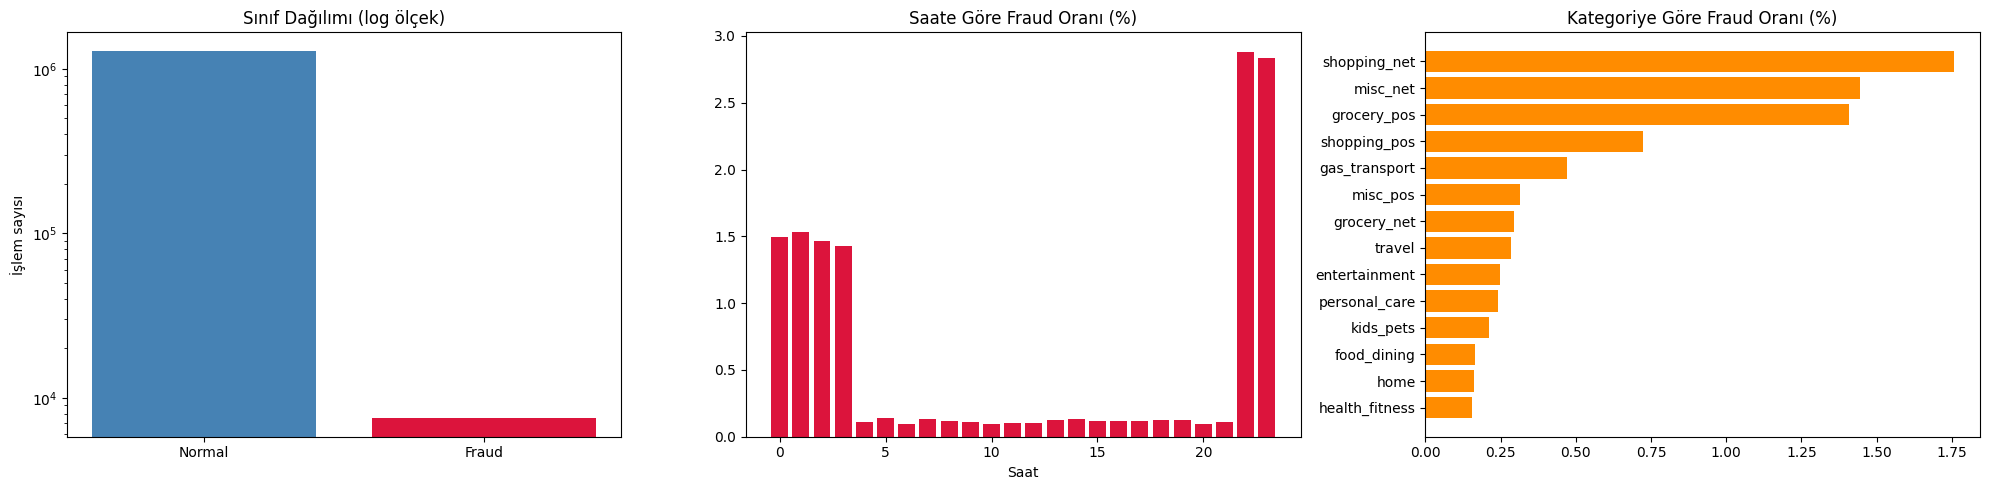

In [11]:
import matplotlib.pyplot as plt

# Saat bazlı fraud oranı
saat_pd = (df.groupBy("saat")
             .agg((F.avg("is_fraud") * 100).alias("oran"))
             .orderBy("saat").toPandas())

# Kategori bazlı fraud oranı
kat_pd = (df.groupBy("category")
            .agg((F.avg("is_fraud") * 100).alias("oran"))
            .orderBy(F.desc("oran")).toPandas())

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1) Sınıf dağılımı
axes[0].bar(["Normal", "Fraud"], [1289169, 7506], color=["steelblue", "crimson"])
axes[0].set_yscale("log")
axes[0].set_title("Sınıf Dağılımı (log ölçek)")
axes[0].set_ylabel("İşlem sayısı")

# 2) Saat bazlı fraud oranı
axes[1].bar(saat_pd["saat"], saat_pd["oran"], color="crimson")
axes[1].set_title("Saate Göre Fraud Oranı (%)")
axes[1].set_xlabel("Saat")

# 3) Kategori bazlı fraud oranı
axes[2].barh(kat_pd["category"], kat_pd["oran"], color="darkorange")
axes[2].invert_yaxis()
axes[2].set_title("Kategoriye Göre Fraud Oranı (%)")

plt.tight_layout()
plt.savefig("dagilim_grafikleri.png", dpi=150)
plt.show()

In [12]:
import time

# Orijinal oranlar
oranlar = {0: 1.0, 1: 1.0}

def ornekle(df, hedef):
    toplam = df.count()
    f = hedef / toplam
    return df.sampleBy("is_fraud", fractions={0: f, 1: f}, seed=42)

# 100 bin ve 1 milyon (örnekleme)
df_100k = ornekle(df, 100_000)
df_1m = ornekle(df, 1_000_000)

# 5 milyon (sentetik büyütme: veriyi tekrarla, tutara küçük gürültü ekle)
tekrar = 4
df_5m = df
for i in range(tekrar - 1):
    df_5m = df_5m.union(
        df.withColumn("amt", F.round(F.col("amt") * (1 + (F.rand(seed=i) - 0.5) * 0.1), 2))
    )

for ad, d in [("100k", df_100k), ("1m", df_1m), ("5m", df_5m)]:
    n = d.count()
    fr = d.filter(F.col("is_fraud") == 1).count()
    print(f"{ad}: {n:,} satır, fraud oranı %{fr/n*100:.3f}")

100k: 99,606 satır, fraud oranı %0.584
1m: 999,596 satır, fraud oranı %0.575
5m: 5,186,700 satır, fraud oranı %0.579


In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
import time, os, subprocess

cikti = "/content/drive/MyDrive/fraud_veri"
os.makedirs(cikti, exist_ok=True)

def klasor_boyut_mb(yol):
    toplam = 0
    for kok, _, dosyalar in os.walk(yol):
        for d in dosyalar:
            toplam += os.path.getsize(os.path.join(kok, d))
    return toplam / 1024 / 1024

sonuclar = []

for ad, d in [("100k", df_100k), ("1m", df_1m), ("5m", df_5m)]:
    for fmt in ["csv", "parquet"]:
        yol = f"{cikti}/{ad}_{fmt}"

        # Yazma süresi
        t0 = time.time()
        if fmt == "csv":
            d.write.mode("overwrite").option("header", True).csv(yol)
        else:
            d.write.mode("overwrite").parquet(yol)
        yazma = time.time() - t0

        # Okuma + agregasyon süresi
        t0 = time.time()
        if fmt == "csv":
            r = spark.read.csv(yol, header=True, inferSchema=True)
        else:
            r = spark.read.parquet(yol)
        r.groupBy("category").agg(F.avg("amt")).collect()
        okuma = time.time() - t0

        sonuclar.append((ad, fmt, round(klasor_boyut_mb(yol), 1), round(yazma, 1), round(okuma, 1)))
        print(sonuclar[-1])

import pandas as pd
tablo = pd.DataFrame(sonuclar, columns=["olcek", "format", "boyut_MB", "yazma_sn", "okuma_sn"])
tablo.to_csv(f"{cikti}/format_karsilastirma.csv", index=False)
print(tablo)

('100k', 'csv', 25.9, 16.6, 4.5)
('100k', 'parquet', 8.1, 16.4, 0.9)
('1m', 'csv', 259.8, 24.3, 14.6)
('1m', 'parquet', 75.7, 22.1, 1.1)
('5m', 'csv', 1348.0, 107.2, 63.9)
('5m', 'parquet', 391.5, 101.8, 4.5)
  olcek   format  boyut_MB  yazma_sn  okuma_sn
0  100k      csv      25.9      16.6       4.5
1  100k  parquet       8.1      16.4       0.9
2    1m      csv     259.8      24.3      14.6
3    1m  parquet      75.7      22.1       1.1
4    5m      csv    1348.0     107.2      63.9
5    5m  parquet     391.5     101.8       4.5


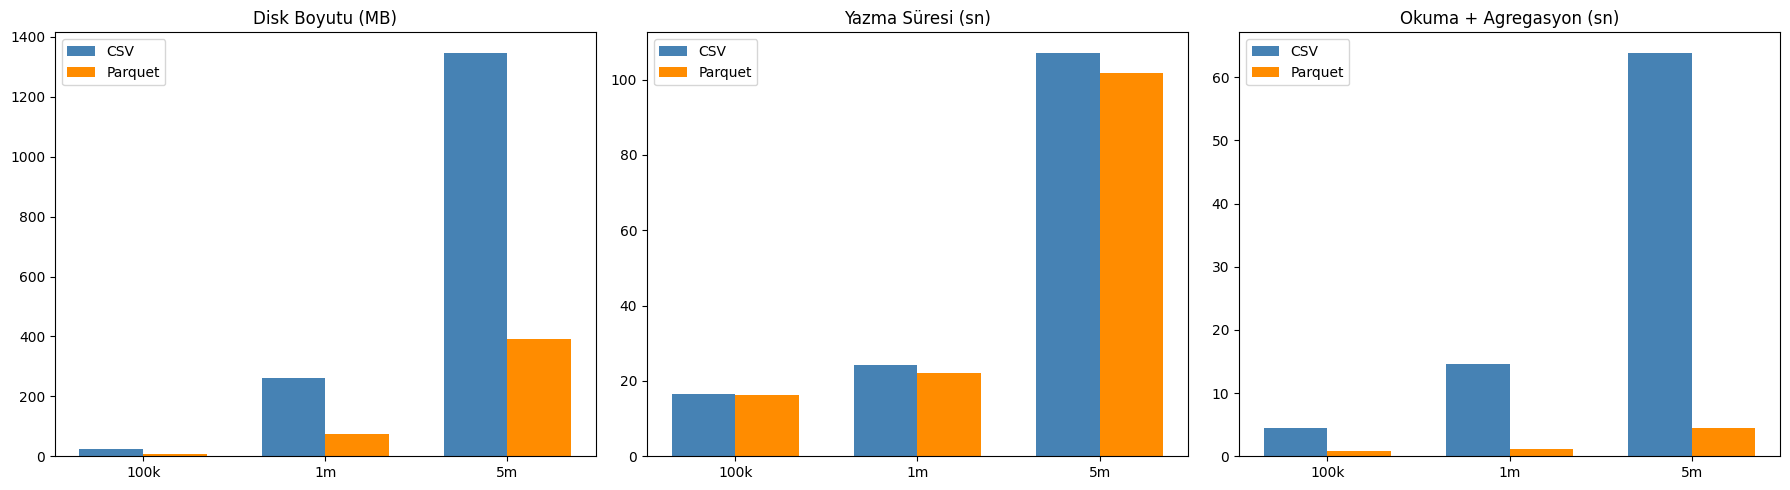

In [15]:
import matplotlib.pyplot as plt

olcekler = ["100k", "1m", "5m"]
csv_t = tablo[tablo.format == "csv"]
pq_t = tablo[tablo.format == "parquet"]
x = range(len(olcekler))
w = 0.35

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, kolon, baslik in zip(axes,
        ["boyut_MB", "yazma_sn", "okuma_sn"],
        ["Disk Boyutu (MB)", "Yazma Süresi (sn)", "Okuma + Agregasyon (sn)"]):
    ax.bar([i - w/2 for i in x], csv_t[kolon], w, label="CSV", color="steelblue")
    ax.bar([i + w/2 for i in x], pq_t[kolon], w, label="Parquet", color="darkorange")
    ax.set_xticks(list(x)); ax.set_xticklabels(olcekler)
    ax.set_title(baslik); ax.legend()

plt.tight_layout()
plt.savefig("format_karsilastirma.png", dpi=150)
plt.show()